# Fundamentals of Data Science - Case Study 5
## Wine Quality Assessment Using Physicochemical Properties

This analysis combines the supplied red and white wine data files for descriptive analysis, then fits a multiple linear regression model using exactly the 11 physicochemical predictors requested in the case-study brief. Wine type is retained for dataset provenance but is not included as a regression predictor.

In [1]:
from pathlib import Path
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings("ignore", category=FutureWarning)
BASE_DIR = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
DATA_DIR = BASE_DIR / "data"
OUTPUT_DIR = BASE_DIR / "outputs"
FIG_DIR = OUTPUT_DIR / "figures"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)
RANDOM_STATE = 42

## 1. Load and audit the data
The two source files are semicolon-delimited. They contain 1,599 red wine samples and 4,898 white wine samples. Records are not dropped just because multiple samples have identical recorded values; repeated profiles can occur in the supplied data. The regression uses the 11 physicochemical attributes and predicts the sensory quality score.

In [2]:
red = pd.read_csv(DATA_DIR / "winequality-red.csv", sep=";")
white = pd.read_csv(DATA_DIR / "winequality-white.csv", sep=";")
red["wine_type"] = "red"
white["wine_type"] = "white"
wine = pd.concat([red, white], ignore_index=True)
features = [c for c in wine.columns if c not in ["quality", "wine_type"]]
target = "quality"
print(f"Combined rows: {len(wine):,}")
print(f"Red wine rows: {len(red):,}; white wine rows: {len(white):,}")
print(f"Predictors: {len(features)}")
print(f"Missing cells: {int(wine.isna().sum().sum())}")
print(f"Repeated rows when wine type is ignored: {int(wine.drop(columns=['wine_type']).duplicated().sum())}")
display(wine.head())
display(wine.groupby("wine_type").agg(samples=("quality", "size"), mean_quality=("quality", "mean"), median_quality=("quality", "median")).round(3))

Combined rows: 6,497
Red wine rows: 1,599; white wine rows: 4,898
Predictors: 11
Missing cells: 0
Repeated rows when wine type is ignored: 1179


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,wine_type
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,red
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,red
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,red
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red


,samples,mean_quality,median_quality
wine_type,,,
red,1599,5.636,6.0
white,4898,5.878,6.0


## 2. Task 1 - Descriptive statistics and relative variability
The coefficient of variation (CV = standard deviation / mean) is used to compare relative variability because the three variables have different units and scales.

In [3]:
summary_rows = []
for col in ["alcohol", "volatile acidity", "residual sugar"]:
    values = wine[col]
    summary_rows.append({
        "attribute": col,
        "mean": values.mean(),
        "median": values.median(),
        "mode": ", ".join(str(v) for v in values.mode().tolist()),
        "standard_deviation": values.std(ddof=1),
        "skewness": values.skew(),
        "coefficient_of_variation": values.std(ddof=1) / values.mean(),
    })
stats_table = pd.DataFrame(summary_rows)
display(stats_table.round(4))
alcohol_quality_r = float(wine["alcohol"].corr(wine["quality"], method="pearson"))
quality_corr = wine[features + [target]].corr(numeric_only=True)[target].drop(target).sort_values(key=lambda s: s.abs(), ascending=False)
print(f"Pearson correlation (alcohol, quality): r = {alcohol_quality_r:.4f}")
print("Attributes ordered by absolute Pearson correlation with quality:")
display(quality_corr.rename("pearson_r").to_frame().round(4))

,attribute,mean,median,mode,standard_deviation,skewness,coefficient_of_variation
0,alcohol,10.4918,10.30,9.5,1.1927,0.5657,0.1137
1,volatile acidity,0.3397,0.29,0.28,0.1646,1.4951,0.4847
2,residual sugar,5.4432,3.00,2.0,4.7578,1.4354,0.8741


Pearson correlation (alcohol, quality): r = 0.4443
Attributes ordered by absolute Pearson correlation with quality:


,pearson_r
alcohol,0.4443
density,-0.3059
volatile acidity,-0.2657
chlorides,-0.2007
citric acid,0.0855
fixed acidity,-0.0767
free sulfur dioxide,0.0555
total sulfur dioxide,-0.0414
sulphates,0.0385
residual sugar,-0.0370


**Statistical interpretation.** Residual sugar has the largest coefficient of variation, so it varies most relative to its mean. Alcohol has a moderate positive correlation with quality: wines with higher alcohol content tend to have higher quality scores in this pooled dataset, although the association is not strong enough to predict an individual score accurately by itself.

## 3. Task 2 - Exploratory data analysis

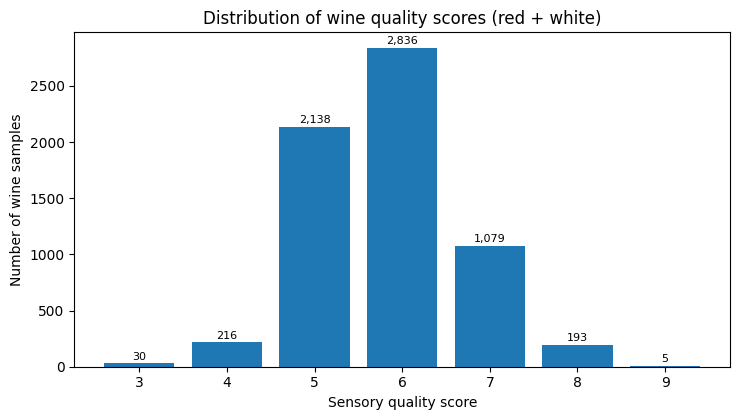

In [4]:
quality_counts = wine["quality"].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(7.5, 4.3))
ax.bar(quality_counts.index.astype(str), quality_counts.values)
ax.set_title("Distribution of wine quality scores (red + white)")
ax.set_xlabel("Sensory quality score")
ax.set_ylabel("Number of wine samples")
for i, v in enumerate(quality_counts.values):
    ax.text(i, v + max(quality_counts.values) * 0.012, f"{v:,}", ha="center", fontsize=8)
fig.tight_layout()
fig.savefig(FIG_DIR / "quality_distribution.png", dpi=180, bbox_inches="tight")
plt.show()

/tmp/ipykernel_1294/1009770319.py:4: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(box_data, labels=[str(q) for q in quality_levels], showfliers=True)


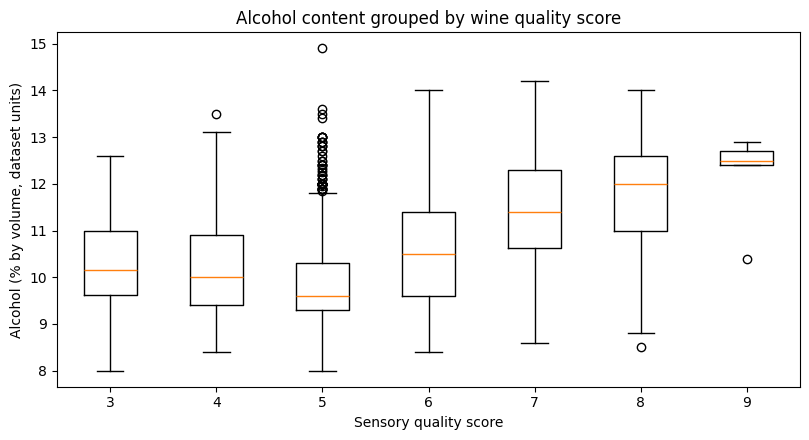

Median alcohol by quality score:


,median_alcohol
quality,
3,10.15
4,10.00
5,9.60
6,10.50
7,11.40
8,12.00
9,12.50


In [5]:
quality_levels = sorted(wine["quality"].unique())
box_data = [wine.loc[wine["quality"] == q, "alcohol"].values for q in quality_levels]
fig, ax = plt.subplots(figsize=(8.2, 4.5))
ax.boxplot(box_data, labels=[str(q) for q in quality_levels], showfliers=True)
ax.set_title("Alcohol content grouped by wine quality score")
ax.set_xlabel("Sensory quality score")
ax.set_ylabel("Alcohol (% by volume, dataset units)")
fig.tight_layout()
fig.savefig(FIG_DIR / "alcohol_by_quality.png", dpi=180, bbox_inches="tight")
plt.show()
alcohol_medians = wine.groupby("quality")["alcohol"].median().round(3)
print("Median alcohol by quality score:")
display(alcohol_medians.rename("median_alcohol").to_frame())

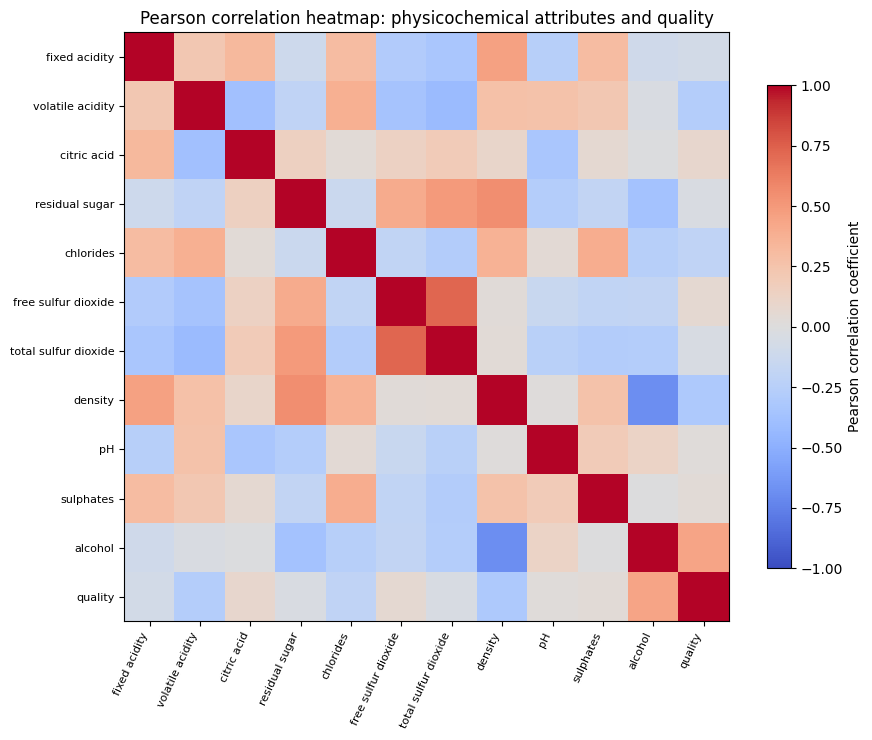

In [6]:
correlation_matrix = wine[features + [target]].corr(numeric_only=True)
fig, ax = plt.subplots(figsize=(9.0, 7.5))
image = ax.imshow(correlation_matrix.values, cmap="coolwarm", vmin=-1, vmax=1, aspect="auto")
ax.set_xticks(np.arange(len(correlation_matrix.columns)))
ax.set_yticks(np.arange(len(correlation_matrix.index)))
ax.set_xticklabels(correlation_matrix.columns, rotation=65, ha="right", fontsize=8)
ax.set_yticklabels(correlation_matrix.index, fontsize=8)
ax.set_title("Pearson correlation heatmap: physicochemical attributes and quality")
colorbar = fig.colorbar(image, ax=ax, shrink=0.82)
colorbar.set_label("Pearson correlation coefficient")
fig.tight_layout()
fig.savefig(FIG_DIR / "correlation_heatmap.png", dpi=180, bbox_inches="tight")
plt.show()

**EDA interpretation.** Scores 5 and 6 dominate the distribution; high and low scores are comparatively rare. The alcohol box plot generally shifts upward as quality increases, although score groups overlap and contain outliers. The two largest absolute Pearson associations with quality are alcohol (positive) and density (negative). These are associations, not causal effects; density is related to several other measured properties.

## 4. Task 3 - Multiple linear regression
A fixed 80/20 train-test split with random state 42 is used. The scaler is fitted only on the training predictors to avoid leaking test-set information. The 11 physicochemical features are retained, as specified in the assignment.

In [7]:
X = wine[features].copy()
y = wine[target].copy()
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
model = LinearRegression()
model.fit(X_train_scaled, y_train)
y_pred = model.predict(X_test_scaled)
metrics = {
    "MAE": float(mean_absolute_error(y_test, y_pred)),
    "MSE": float(mean_squared_error(y_test, y_pred)),
    "RMSE": float(mean_squared_error(y_test, y_pred) ** 0.5),
    "R2": float(r2_score(y_test, y_pred)),
}
print("Test-set model evaluation")
display(pd.DataFrame([metrics]).round(4))
coef_table = pd.DataFrame({"attribute": features, "standardized_coefficient": model.coef_})
coef_table["absolute_coefficient"] = coef_table["standardized_coefficient"].abs()
coef_table = coef_table.sort_values("absolute_coefficient", ascending=False).reset_index(drop=True)
print("Standardized predictor coefficients (change in predicted quality units per 1 SD increase in predictor, conditional on other included features):")
display(coef_table.round(4))

Test-set model evaluation


,MAE,MSE,RMSE,R2
0,0.5659,0.5467,0.7394,0.2598


Standardized predictor coefficients (change in predicted quality units per 1 SD increase in predictor, conditional on other included features):


,attribute,standardized_coefficient,absolute_coefficient
0,alcohol,0.3224,0.3224
1,residual sugar,0.2204,0.2204
2,volatile acidity,-0.2190,0.2190
3,density,-0.1773,0.1773
4,total sulfur dioxide,-0.1495,0.1495
5,free sulfur dioxide,0.1225,0.1225
6,sulphates,0.1202,0.1202
7,fixed acidity,0.1017,0.1017
8,pH,0.0771,0.0771
9,citric acid,-0.0208,0.0208


### Multicollinearity diagnostic
Standardized coefficients describe conditional model effects. Their interpretation can be unstable when predictors are correlated, so pairwise predictor correlations and variance inflation factors (VIF) are calculated before drawing conclusions from coefficient signs or magnitudes.

In [8]:
predictor_corr = X_train.corr()
upper = predictor_corr.where(np.triu(np.ones(predictor_corr.shape), k=1).astype(bool))
pair_rows = []
for row in upper.stack().sort_values(key=lambda s: s.abs(), ascending=False).head(8).items():
    (a, b), val = row
    pair_rows.append({"predictor_1": a, "predictor_2": b, "pearson_r": val, "absolute_r": abs(val)})
predictor_pairs = pd.DataFrame(pair_rows)
print("Largest absolute pairwise predictor correlations (training set)")
display(predictor_pairs.round(4))

vif_rows = []
for col in features:
    other_cols = [c for c in features if c != col]
    aux = LinearRegression().fit(X_train[other_cols], X_train[col])
    r2_aux = r2_score(X_train[col], aux.predict(X_train[other_cols]))
    vif = float(1.0 / max(1.0 - r2_aux, 1e-12))
    vif_rows.append({"attribute": col, "VIF": vif})
vif_table = pd.DataFrame(vif_rows).sort_values("VIF", ascending=False).reset_index(drop=True)
print("Variance inflation factors (training predictors)")
display(vif_table.round(3))

Largest absolute pairwise predictor correlations (training set)


,predictor_1,predictor_2,pearson_r,absolute_r
0,free sulfur dioxide,total sulfur dioxide,0.7243,0.7243
1,density,alcohol,-0.6836,0.6836
2,residual sugar,density,0.5628,0.5628
3,residual sugar,total sulfur dioxide,0.4921,0.4921
4,fixed acidity,density,0.4515,0.4515
5,volatile acidity,total sulfur dioxide,-0.4105,0.4105
6,chlorides,sulphates,0.4037,0.4037
7,residual sugar,free sulfur dioxide,0.4020,0.4020


Variance inflation factors (training predictors)


,attribute,VIF
0,density,15.506
1,residual sugar,7.196
2,fixed acidity,4.741
3,alcohol,4.616
4,total sulfur dioxide,2.961
5,pH,2.471
6,free sulfur dioxide,2.159
7,volatile acidity,1.936
8,chlorides,1.646
9,citric acid,1.614


**Model interpretation.** Alcohol has the largest positive standardized coefficient. Residual sugar and volatile acidity have coefficients of similar absolute size but opposite signs, so coefficient ranking is conditional on the other included predictors. Correlated physicochemical measures (notably total and free sulfur dioxide, and density-related measures) can inflate coefficient uncertainty; the coefficients should not be read as causal effects.

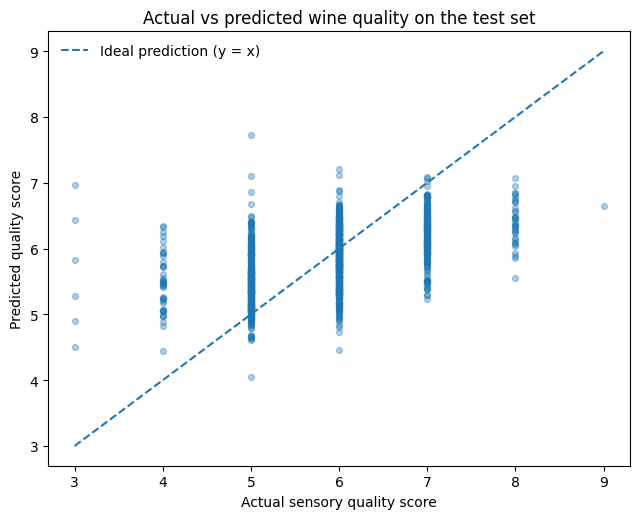

Observed test quality range: 3 to 9
Predicted test quality range: 4.05 to 7.72


In [9]:
fig, ax = plt.subplots(figsize=(6.5, 5.3))
ax.scatter(y_test, y_pred, alpha=0.35, s=18)
low = min(float(y_test.min()), float(y_pred.min()))
high = max(float(y_test.max()), float(y_pred.max()))
ax.plot([low, high], [low, high], linestyle="--", linewidth=1.5, label="Ideal prediction (y = x)")
ax.set_title("Actual vs predicted wine quality on the test set")
ax.set_xlabel("Actual sensory quality score")
ax.set_ylabel("Predicted quality score")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(FIG_DIR / "actual_vs_predicted.png", dpi=180, bbox_inches="tight")
plt.show()
print(f"Observed test quality range: {int(y_test.min())} to {int(y_test.max())}")
print(f"Predicted test quality range: {y_pred.min():.2f} to {y_pred.max():.2f}")

**Prediction-plot interpretation.** Predictions concentrate around the middle of the observed score range and do not reproduce the rare extreme scores well. Combined with the test-set R-squared, this indicates limited explanatory/predictive power for individual wines. A useful role is as a preliminary screening signal, not a replacement for sensory assessment.

## 5. Task 4 - Business decision-making and limitations
**Recommendation:** monitor alcohol and density as candidate screening measurements because they have the strongest absolute Pearson associations with quality in the pooled dataset. Density must be interpreted alongside other measurements because it is correlated with several predictors. A laboratory screen should be calibrated against sensory scores and reviewed by domain experts.

**Reliability:** the model's test metrics quantify errors on a held-out subset. MAE is the average absolute score error, RMSE penalizes larger errors, and R-squared is the proportion of test-set quality variance explained by the model. These metrics support use as an assistive screening flag only, not replacement of sensory evaluation.

**Limitations:** (1) red and white wines are pooled while wine type is not a predictor, and white wines make up most rows; (2) quality scores are imbalanced and extreme grades are rare; (3) linear regression may miss nonlinear effects and interactions; (4) physicochemical data do not include brand, grape, region, price, or other possible quality drivers.

In [10]:
print("Final metrics:", {k: round(v, 4) for k, v in metrics.items()})
print("Top 2 absolute Pearson correlations with quality:")
print(quality_corr.head(2).round(4).to_dict())
print("Top standardized coefficients:")
print(coef_table.head(4)[["attribute", "standardized_coefficient"]].round(4).to_dict(orient="records"))
summary = {
    "rows": int(len(wine)),
    "red_rows": int(len(red)),
    "white_rows": int(len(white)),
    "missing_cells": int(wine.isna().sum().sum()),
    "duplicates_ignoring_type": int(wine.drop(columns=["wine_type"]).duplicated().sum()),
    "stats": stats_table.replace({np.nan: None}).to_dict(orient="records"),
    "alcohol_quality_pearson_r": alcohol_quality_r,
    "quality_correlations": quality_corr.to_dict(),
    "quality_distribution": {str(int(k)): int(v) for k, v in quality_counts.items()},
    "alcohol_medians_by_quality": {str(int(k)): float(v) for k, v in alcohol_medians.items()},
    "metrics": metrics,
    "standardized_coefficients": coef_table.replace({np.nan: None}).to_dict(orient="records"),
    "predictor_correlations": predictor_pairs.replace({np.nan: None}).to_dict(orient="records"),
    "vif": vif_table.replace({np.nan: None}).to_dict(orient="records"),
    "test_actual_min": int(y_test.min()),
    "test_actual_max": int(y_test.max()),
    "test_predicted_min": float(y_pred.min()),
    "test_predicted_max": float(y_pred.max()),
    "train_size": int(len(X_train)),
    "test_size": int(len(X_test)),
    "random_state": RANDOM_STATE,
}
with open(OUTPUT_DIR / "results_summary.json", "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=2, default=lambda o: float(o) if isinstance(o, (np.floating,)) else int(o) if isinstance(o, (np.integer,)) else str(o))
print(f"Saved figures and result summary under: {OUTPUT_DIR}")

Final metrics: {'MAE': 0.5659, 'MSE': 0.5467, 'RMSE': 0.7394, 'R2': 0.2598}
Top 2 absolute Pearson correlations with quality:
{'alcohol': 0.4443, 'density': -0.3059}
Top standardized coefficients:
[{'attribute': 'alcohol', 'standardized_coefficient': 0.3224}, {'attribute': 'residual sugar', 'standardized_coefficient': 0.2204}, {'attribute': 'volatile acidity', 'standardized_coefficient': -0.219}, {'attribute': 'density', 'standardized_coefficient': -0.1773}]
Saved figures and result summary under: /mnt/data/fds_work/case5/outputs
